# Machine Learning Assignment 2 – Network Intrusion Detection

### AIMLZG565 — Machine Learning | M.Tech. AIML, BITS Pilani WILP

**Student:** Munnawar Nagarbawadi  
**BITS Student ID:** 2026aj05664  
**Semester:** 1 (2026–27)

---

## 1. Problem statement

The aim of this assignment is to build and compare five classification models using the RT-IoT2022 network traffic dataset. The target column is `Attack_type`, which identifies the network traffic category for each record.

The models will be evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC). The trained pipelines will also be saved so they can be used later in the Streamlit application.

## 2. Dataset

The dataset used in this project is **RT-IoT2022 – Network Intrusion Detection**, downloaded from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/942/rt-iot2022).

The CSV used here contains network-flow measurements, two categorical input columns (`proto` and `service`) and the target column `Attack_type`. The dataset will be checked before any cleaning or model training is done.

## 3. Models to be compared

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (linear SVM using hinge loss)

The analysis and model runs are kept in the order they were carried out: first understanding the data, then preparing the train/test files, and finally training and evaluating each model.

## 4. Import libraries and connect Google Drive

In [1]:
import sys
import sklearn

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

Python: /home/s2026aj05664/workspace/Munnawar/.venv/bin/python
Scikit-learn: 1.6.1


In [2]:
# Importing the libraries used throughout the notebook

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.exceptions import ConvergenceWarning

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)

import sklearn
print('Scikit-learn version:', sklearn.__version__)

Scikit-learn version: 1.6.1


In [3]:
# Setting up the project paths for BITS Virtual Lab

from pathlib import Path

PROJECT_DIR = Path(
    "/home/s2026aj05664/workspace/Munnawar/Machine Learning"
)

# Path of the original dataset
RAW_DATA_PATH = PROJECT_DIR / "RT_IOT2022.csv"

# Folders to store the generated files
SPLIT_DIR = PROJECT_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "model"
RESULTS_DIR = PROJECT_DIR / "results"
CM_DIR = RESULTS_DIR / "confusion_matrices"
REPORT_DIR = RESULTS_DIR / "classification_reports"

# Creating the required folders if they do not already exist
for folder in [SPLIT_DIR, MODEL_DIR, RESULTS_DIR, CM_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset path:", RAW_DATA_PATH)
print("Dataset exists:", RAW_DATA_PATH.is_file())

Project directory: /home/s2026aj05664/workspace/Munnawar/Machine Learning
Dataset path: /home/s2026aj05664/workspace/Munnawar/Machine Learning/RT_IOT2022.csv
Dataset exists: True


## 5. Load the dataset and check its structure

In [4]:
# Reading the dataset into a dataframe

df = pd.read_csv(RAW_DATA_PATH)

print("Dataset imported successfully.")
display(df.head())

Dataset imported successfully.


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.

In [5]:
# Checking the number of records and columns

rows, columns = df.shape
print("Number of records:", rows)
print("Number of columns:", columns)

Number of records: 123117
Number of columns: 85


In [6]:
# Checking column names, data types and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 85 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  object 
 4   service                   123117 non-null  object 
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio             123117 non-null  f

In [7]:
# Counting numerical and categorical columns

initial_numeric = df.select_dtypes(include=np.number).columns.tolist()
initial_categorical = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", len(initial_numeric))
print("Categorical columns:", len(initial_categorical))
print("Categorical column names:", initial_categorical)

Numerical columns: 82
Categorical columns: 3
Categorical column names: ['proto', 'service', 'Attack_type']


In [8]:
# Checking whether any columns contain missing values

missing_summary = df.isna().sum()
print("Total missing values:", int(missing_summary.sum()))

display(missing_summary[missing_summary > 0].to_frame("Missing values"))

Total missing values: 0


,Missing values


In [9]:
# Checking exact duplicate rows after excluding the extra index column

df_without_index = df.drop(columns=['Unnamed: 0'], errors='ignore').copy()
exact_duplicates = df_without_index.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

Exact duplicate rows: 5195


In [10]:
# Checking the target labels and their record counts

print("Number of attack categories:", df['Attack_type'].nunique())
attack_counts = df['Attack_type'].value_counts()
display(attack_counts.to_frame("Record count"))

Number of attack categories: 12


,Record count
Attack_type,
DOS_SYN_Hping,94659
Thing_Speak,8108
ARP_poisioning,7750
MQTT_Publish,4146
NMAP_UDP_SCAN,2590
NMAP_XMAS_TREE_SCAN,2010
NMAP_OS_DETECTION,2000
NMAP_TCP_scan,1002
DDOS_Slowloris,534


,Attack_type,Count,Percentage
0,DOS_SYN_Hping,94659,76.89
1,Thing_Speak,8108,6.59
2,ARP_poisioning,7750,6.29
3,MQTT_Publish,4146,3.37
4,NMAP_UDP_SCAN,2590,2.10
5,NMAP_XMAS_TREE_SCAN,2010,1.63
6,NMAP_OS_DETECTION,2000,1.62
7,NMAP_TCP_scan,1002,0.81
8,DDOS_Slowloris,534,0.43
9,Wipro_bulb,253,0.21


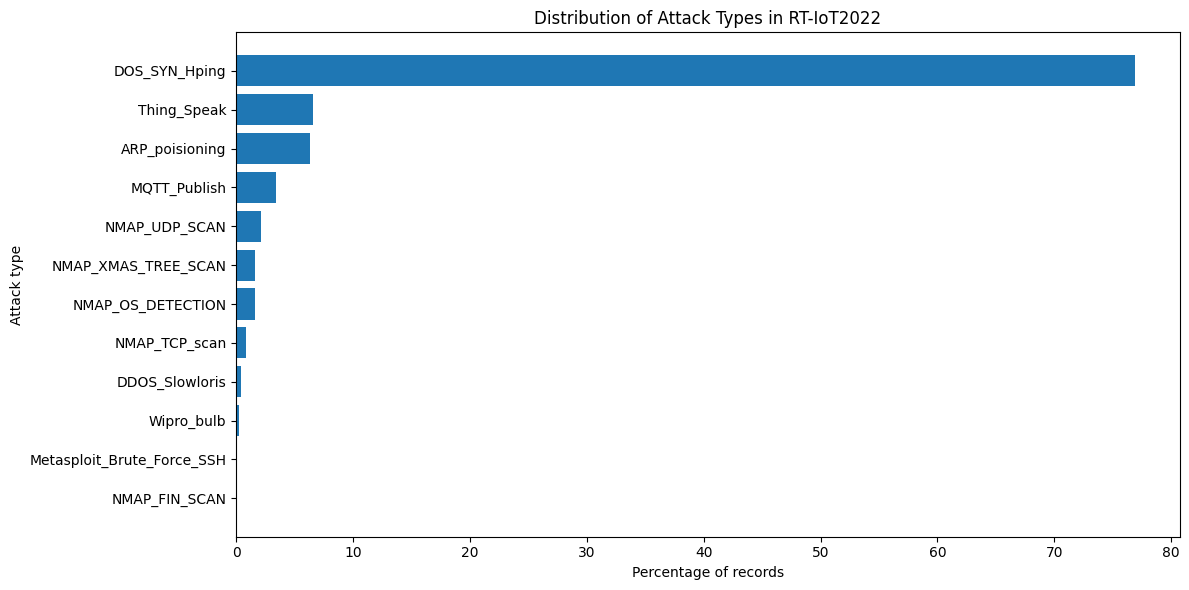

In [11]:
# Plotting the class distribution to see how the records are spread

class_distribution = attack_counts.rename_axis('Attack_type').reset_index(name='Count')
class_distribution['Percentage'] = (class_distribution['Count'] / len(df) * 100).round(2)

display(class_distribution)

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(class_distribution['Attack_type'], class_distribution['Percentage'])
ax.set_xlabel('Percentage of records')
ax.set_ylabel('Attack type')
ax.set_title('Distribution of Attack Types in RT-IoT2022')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
plt.close(fig)

## 6. Check the index column, constant features and repeated records

In [12]:
# Checking whether the extra index column contains useful information

if 'Unnamed: 0' in df.columns:
    index_summary = (
        df.groupby('Attack_type')['Unnamed: 0']
        .agg(
            total_records='count',
            unique_values='nunique',
            minimum='min',
            maximum='max'
        )
        .sort_values('total_records', ascending=False)
    )
    display(index_summary)
else:
    print("The extra index column is not present in this file.")

,total_records,unique_values,minimum,maximum
Attack_type,,,,
DOS_SYN_Hping,94659,94659,0,94658
Thing_Speak,8108,8108,0,8107
ARP_poisioning,7750,7750,0,7749
MQTT_Publish,4146,4146,0,4145
NMAP_UDP_SCAN,2590,2590,0,2589
NMAP_XMAS_TREE_SCAN,2010,2010,0,2009
NMAP_OS_DETECTION,2000,2000,0,1999
NMAP_TCP_scan,1002,1002,0,1001
DDOS_Slowloris,534,534,0,533


In [13]:
# Looking for input features that have only one unique value

feature_data = df.drop(
    columns=['Unnamed: 0', 'Attack_type'],
    errors='ignore'
)

unique_counts = feature_data.nunique()
constant_features = unique_counts[unique_counts == 1]

print("Number of constant features:", len(constant_features))
display(constant_features.to_frame("Unique values"))

Number of constant features: 1


,Unique values
bwd_URG_flag_count,1


In [14]:
# Grouping identical input-feature combinations to check repeated and conflicting labels

# The extra index is left out because it is not a network traffic measurement.
duplicate_features = df_without_index.drop(columns=['Attack_type'])
feature_group_ids = duplicate_features.groupby(
    duplicate_features.columns.tolist(),
    dropna=False,
    sort=False
).ngroup()

group_check = pd.DataFrame({
    'feature_group_id': feature_group_ids,
    'Attack_type': df_without_index['Attack_type'].values
})

group_summary = (
    group_check.groupby('feature_group_id')
    .agg(
        total_records=('Attack_type', 'size'),
        number_of_labels=('Attack_type', 'nunique'),
        attack_labels=('Attack_type', lambda values: ', '.join(sorted(values.unique())))
    )
)

repeated_groups = group_summary[group_summary['total_records'] > 1]
conflicting_groups = repeated_groups[repeated_groups['number_of_labels'] > 1]

print("Repeated feature combinations:", len(repeated_groups))
print("Records in repeated combinations:", int(repeated_groups['total_records'].sum()))
print("Feature combinations with different labels:", len(conflicting_groups))

# Showing only the groups where identical features have different target labels
display(conflicting_groups.reset_index())

Repeated feature combinations: 4956
Records in repeated combinations: 10158
Feature combinations with different labels: 6


,feature_group_id,total_records,number_of_labels,attack_labels
0,4200,75,3,"ARP_poisioning, DDOS_Slowloris, Thing_Speak"
1,4597,24,2,"ARP_poisioning, Thing_Speak"
2,4975,4,2,"ARP_poisioning, Thing_Speak"
3,4976,4,2,"ARP_poisioning, Thing_Speak"
4,14484,17,2,"ARP_poisioning, NMAP_UDP_SCAN"
5,110289,4,2,"Metasploit_Brute_Force_SSH, NMAP_UDP_SCAN"


### Initial observations

- The file contains **123,117 records** and **85 columns**.
- There are no missing values in the uploaded CSV.
- `Unnamed: 0` behaves like an index that restarts within each attack category, so it will not be used as a model feature.
- `bwd_URG_flag_count` is constant and will also be removed before training.
- Repeated input-feature combinations are present. Six combinations have more than one target label, so those records need to be handled before the train/test split.
- The target contains 12 attack categories and is highly imbalanced. `DOS_SYN_Hping` is the largest category.

The checks below look at the feature distributions before deciding how to prepare them for the models.

## 7. Explore the input features

In [15]:
# Removing the index and constant feature for the feature-level analysis

df_eda = df.drop(
    columns=['Unnamed: 0', 'bwd_URG_flag_count'],
    errors='ignore'
).copy()

X_eda = df_eda.drop(columns=['Attack_type'])
y_eda = df_eda['Attack_type']

numerical_features = X_eda.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_eda.select_dtypes(exclude=np.number).columns.tolist()

print("Input features:", X_eda.shape[1])
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Categorical columns:", categorical_features)

Input features: 82
Numerical features: 80
Categorical features: 2
Categorical columns: ['proto', 'service']


In [16]:
# Checking the category counts and percentages for proto and service

for column in categorical_features:
    category_summary = (
        df_eda[column]
        .value_counts()
        .rename_axis(column)
        .reset_index(name='Count')
    )
    category_summary['Percentage'] = (category_summary['Count'] / len(df_eda) * 100).round(2)

    print(f"\nDistribution of {column}")
    display(category_summary)


Distribution of proto


,proto,Count,Percentage
0,tcp,110427,89.69
1,udp,12633,10.26
2,icmp,57,0.05



Distribution of service


,service,Count,Percentage
0,-,102861,83.55
1,dns,9753,7.92
2,mqtt,4132,3.36
3,http,3464,2.81
4,ssl,2663,2.16
5,ntp,121,0.10
6,dhcp,50,0.04
7,irc,43,0.03
8,ssh,28,0.02
9,radius,2,0.00


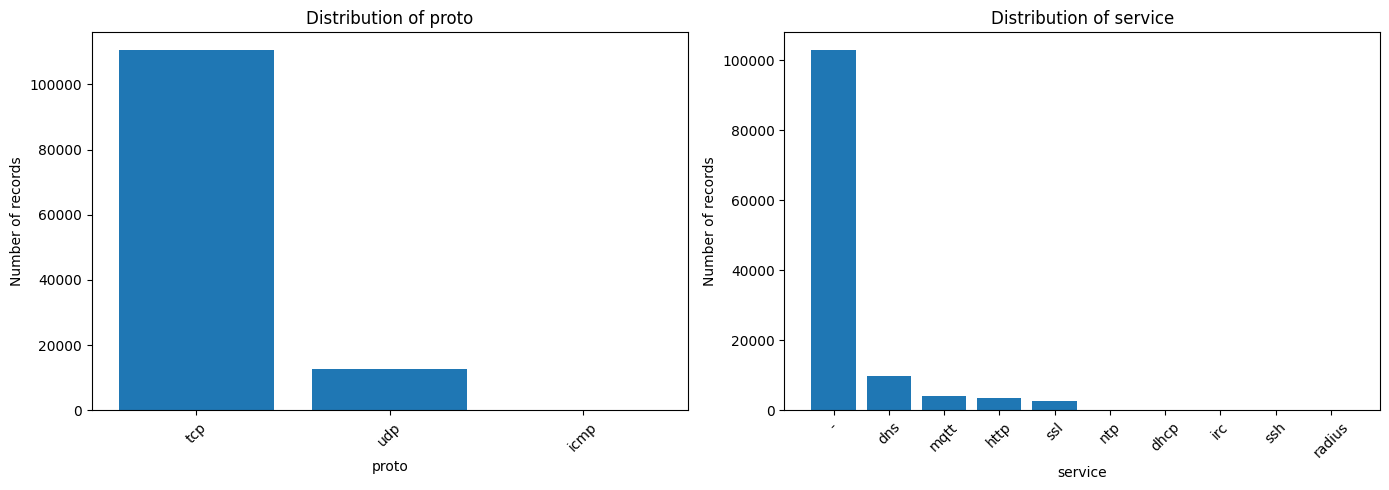

In [17]:
# Plotting the two categorical features

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, categorical_features):
    counts = df_eda[column].value_counts()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Number of records')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
plt.close(fig)

In [18]:
# Looking at the main statistics for the numerical features

display(X_eda[numerical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,37221.000000,50971.000000,6.553500e+04
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,21.000000,21.000000,6.538900e+04
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,0.000004,0.000005,2.172834e+04
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000,1.000000,4.345000e+03
bwd_pkts_tot,123117.0,1.909509e+00,3.301831e+01,0.0,1.000000,1.000000,1.000000,1.011200e+04
...,...,...,...,...,...,...,...,...
idle.avg,123117.0,1.664985e+06,9.007064e+06,0.0,0.000000,0.000000,0.000000,3.000000e+08
idle.std,123117.0,4.550183e+04,1.091361e+06,0.0,0.000000,0.000000,0.000000,1.208029e+08
fwd_init_window_size,123117.0,6.118905e+03,1.871631e+04,0.0,64.000000,64.000000,64.000000,6.553500e+04
bwd_init_window_size,123117.0,2.739776e+03,1.001885e+04,0.0,0.000000,0.000000,0.000000,6.553500e+04


In [19]:
# Checking which numerical features have the highest skewness

feature_skewness = X_eda[numerical_features].skew().sort_values(ascending=False)
display(feature_skewness.head(15).to_frame('Skewness'))

,Skewness
bwd_bulk_bytes,340.497528
bwd_bulk_packets,340.490987
active.std,287.992755
bwd_pkts_payload.tot,280.814630
flow_pkts_payload.tot,271.972274
bwd_header_size_tot,269.075835
bwd_data_pkts_tot,264.030712
bwd_pkts_tot,249.909345
fwd_iat.min,238.881011
active.max,234.461542


In [20]:
# Checking how often zero values occur in numerical features

zero_summary = pd.DataFrame({
    'Zero_Count': (X_eda[numerical_features] == 0).sum(),
    'Zero_Percentage': (X_eda[numerical_features] == 0).mean().mul(100).round(2),
    'Unique_Values': X_eda[numerical_features].nunique()
}).sort_values('Zero_Percentage', ascending=False)

display(zero_summary.head(20))

,Zero_Count,Zero_Percentage,Unique_Values
flow_CWR_flag_count,123046,99.94,5
flow_ECE_flag_count,123045,99.94,5
fwd_bulk_bytes,122871,99.80,220
fwd_bulk_packets,122871,99.80,56
fwd_bulk_rate,122871,99.80,247
idle.std,122100,99.17,1001
bwd_bulk_packets,122010,99.10,137
bwd_bulk_rate,122010,99.10,926
bwd_bulk_bytes,122010,99.10,459
active.std,121427,98.63,1673


In [21]:
# Checking for negative values before using log1p in the distribution plots

negative_summary = X_eda[numerical_features].lt(0).sum()
negative_summary = negative_summary[negative_summary > 0]

print("Features containing negative values:", len(negative_summary))
display(negative_summary.to_frame('Negative count'))

Features containing negative values: 0


,Negative count


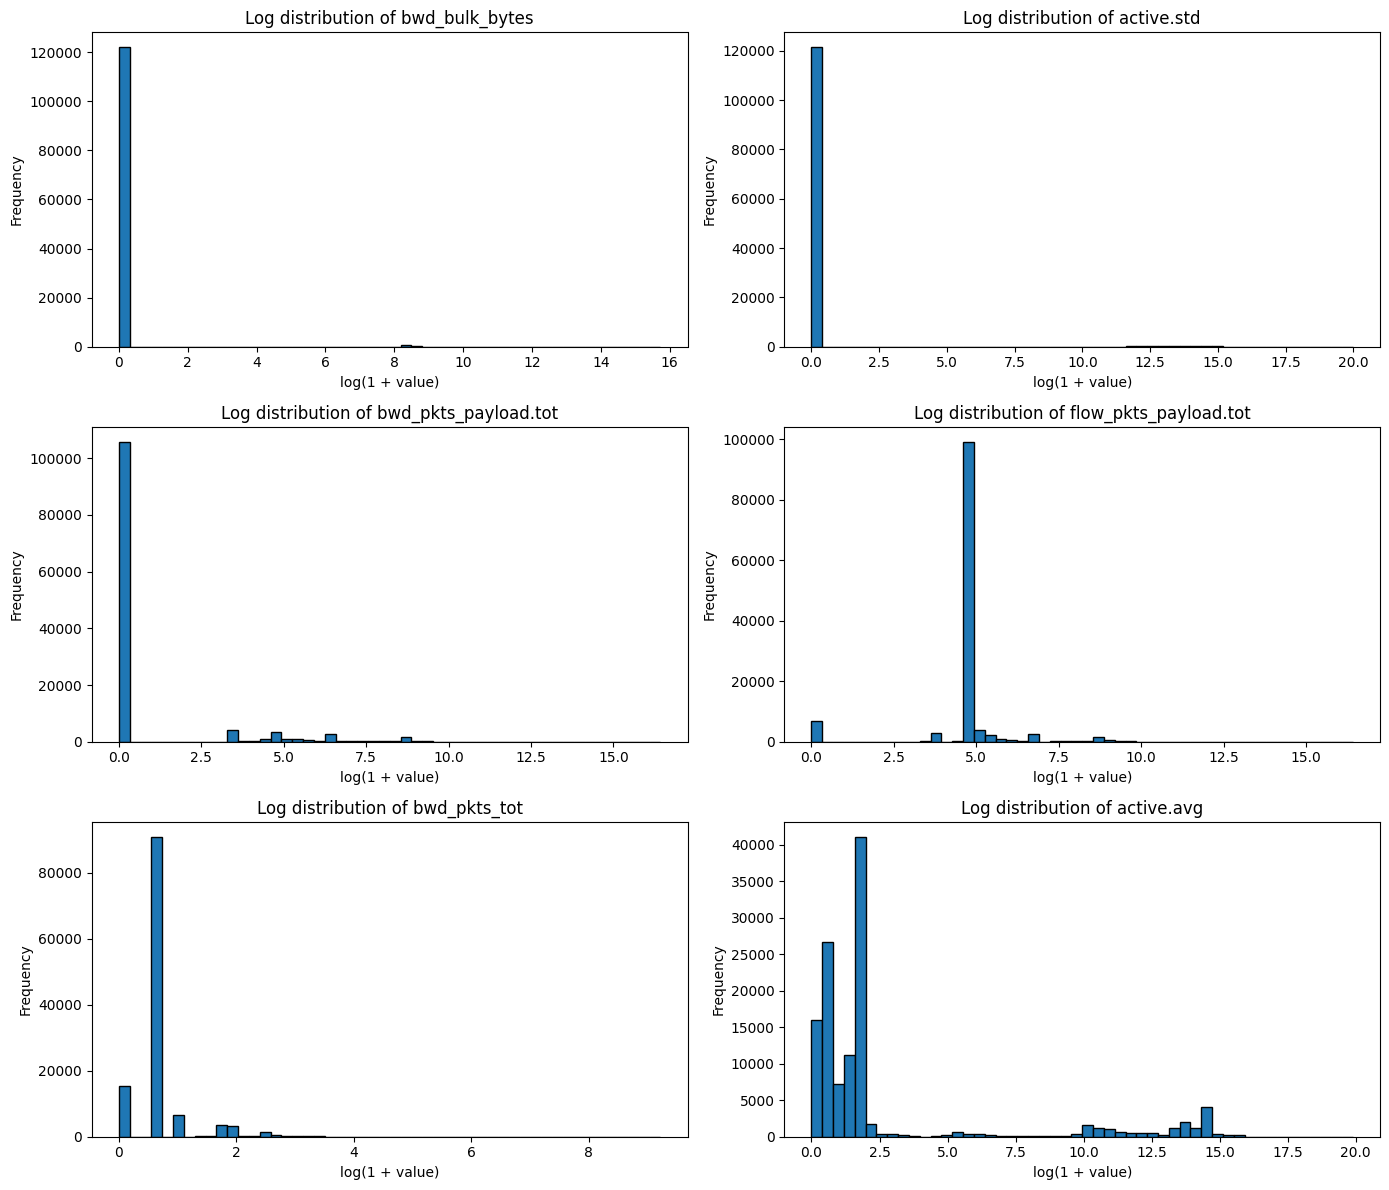

In [22]:
# Plotting a few heavily skewed features after log1p transformation

selected_skewed_features = [
    'bwd_bulk_bytes',
    'active.std',
    'bwd_pkts_payload.tot',
    'flow_pkts_payload.tot',
    'bwd_pkts_tot',
    'active.avg'
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, column in zip(axes.flatten(), selected_skewed_features):
    values = np.log1p(X_eda[column])
    ax.hist(values, bins=50, edgecolor='black')
    ax.set_title(f'Log distribution of {column}')
    ax.set_xlabel('log(1 + value)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()
plt.close(fig)

In [23]:
# Comparing feature ranges at different percentiles

percentile_summary = X_eda[numerical_features].quantile(
    [0.00, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
).T

percentile_summary.columns = [
    'Minimum', '25%', '50%', '75%', '90%', '95%', '99%', 'Maximum'
]

display(percentile_summary)

,Minimum,25%,50%,75%,90%,95%,99%,Maximum
id.orig_p,0.0,17702.000000,37221.000000,50971.000000,59099.400000,61750.200000,6.457684e+04,6.553500e+04
id.resp_p,0.0,21.000000,21.000000,21.000000,1092.000000,5353.000000,3.158340e+04,6.538900e+04
flow_duration,0.0,0.000001,0.000004,0.000005,0.056464,2.899319,6.204395e+01,2.172834e+04
fwd_pkts_tot,0.0,1.000000,1.000000,1.000000,2.000000,9.000000,1.500000e+01,4.345000e+03
bwd_pkts_tot,0.0,1.000000,1.000000,1.000000,2.000000,6.000000,1.300000e+01,1.011200e+04
...,...,...,...,...,...,...,...,...
idle.avg,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.980210e+07,3.000000e+08
idle.std,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,1.208029e+08
fwd_init_window_size,0.0,64.000000,64.000000,64.000000,1024.000000,64240.000000,6.424000e+04,6.553500e+04
bwd_init_window_size,0.0,0.000000,0.000000,0.000000,0.000000,26847.000000,6.516000e+04,6.553500e+04


In [24]:
# Calculating Spearman correlation between numerical features

correlation_matrix = X_eda[numerical_features].corr(method='spearman')
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

correlation_pairs = upper_triangle.stack().reset_index()
correlation_pairs.columns = ['Feature_1', 'Feature_2', 'Correlation']
correlation_pairs['Absolute_Correlation'] = correlation_pairs['Correlation'].abs()
correlation_pairs = correlation_pairs.sort_values(
    'Absolute_Correlation', ascending=False
)

display(correlation_pairs.head(20))

,Feature_1,Feature_2,Correlation,Absolute_Correlation
2992,fwd_bulk_bytes,fwd_bulk_rate,0.999999,0.999999
2990,fwd_bulk_bytes,fwd_bulk_packets,0.999999,0.999999
3025,fwd_bulk_packets,fwd_bulk_rate,0.999999,0.999999
3094,active.max,active.tot,0.999994,0.999994
3140,idle.max,idle.avg,0.999994,0.999994
3008,bwd_bulk_bytes,bwd_bulk_packets,0.999990,0.999990
3134,idle.min,idle.avg,0.999981,0.999981
3010,bwd_bulk_bytes,bwd_bulk_rate,0.999979,0.999979
3041,bwd_bulk_packets,bwd_bulk_rate,0.999970,0.999970
533,fwd_pkts_per_sec,flow_pkts_per_sec,0.999963,0.999963


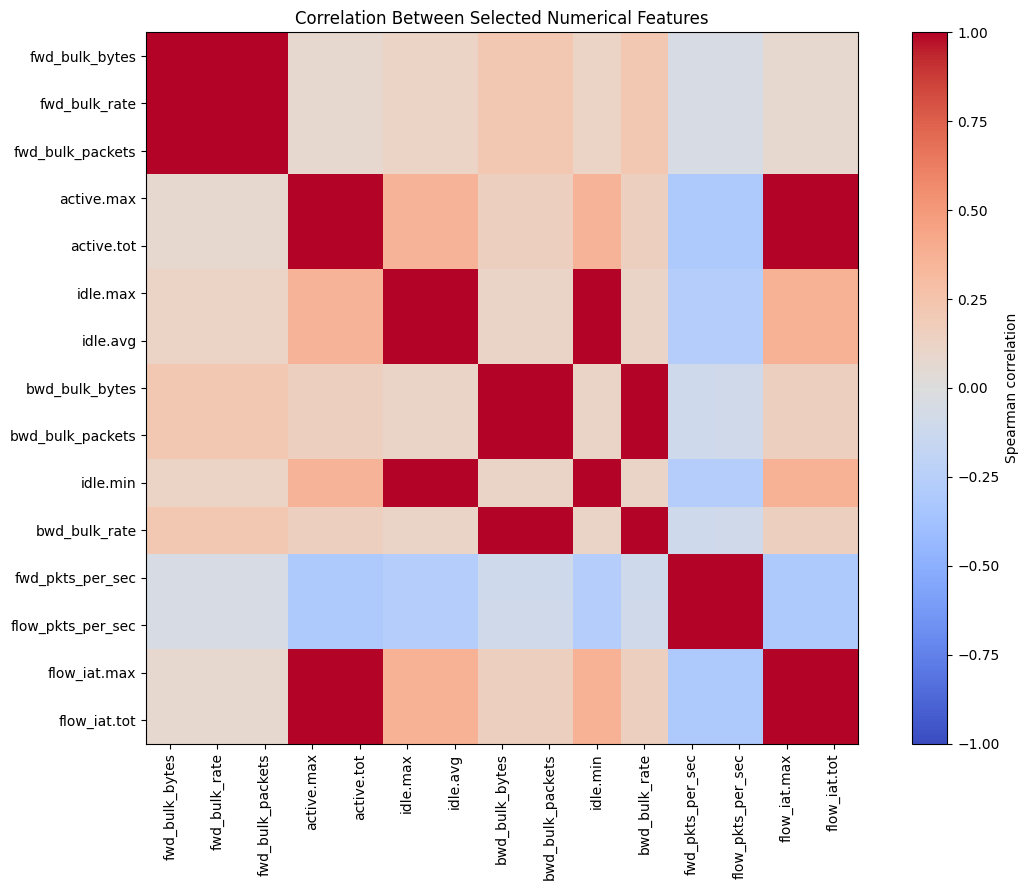

In [25]:
# Plotting a smaller correlation matrix using the strongest feature pairs

top_correlated_features = pd.unique(
    correlation_pairs.head(12)[['Feature_1', 'Feature_2']].values.ravel()
)
small_corr_matrix = correlation_matrix.loc[
    top_correlated_features, top_correlated_features
]

fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(small_corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, label='Spearman correlation')
ax.set_xticks(range(len(top_correlated_features)))
ax.set_xticklabels(top_correlated_features, rotation=90)
ax.set_yticks(range(len(top_correlated_features)))
ax.set_yticklabels(top_correlated_features)
ax.set_title('Correlation Between Selected Numerical Features')
plt.tight_layout()
plt.show()
plt.close(fig)

In [26]:
# Checking how protocol values are distributed within each attack category

protocol_distribution = pd.crosstab(
    df_eda['Attack_type'], df_eda['proto'], normalize='index'
).mul(100)

display(protocol_distribution.round(2))

proto,icmp,tcp,udp
Attack_type,,,
ARP_poisioning,0.10,24.86,75.03
DDOS_Slowloris,0.00,99.06,0.94
DOS_SYN_Hping,0.00,100.00,0.00
MQTT_Publish,0.00,100.00,0.00
Metasploit_Brute_Force_SSH,0.00,78.38,21.62
NMAP_FIN_SCAN,0.00,89.29,10.71
NMAP_OS_DETECTION,0.00,100.00,0.00
NMAP_TCP_scan,0.00,100.00,0.00
NMAP_UDP_SCAN,0.08,5.48,94.44


In [27]:
# Checking how service values are distributed within each attack category

service_distribution = pd.crosstab(
    df_eda['Attack_type'], df_eda['service'], normalize='index'
).mul(100)

display(service_distribution.round(2))

service,-,dhcp,dns,http,irc,mqtt,ntp,radius,ssh,ssl
Attack_type,,,,,,,,,,
ARP_poisioning,7.05,0.34,72.04,1.66,0.0,0.00,0.09,0.00,0.00,18.83
DDOS_Slowloris,1.12,0.37,0.56,97.94,0.0,0.00,0.00,0.00,0.00,0.00
DOS_SYN_Hping,100.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
MQTT_Publish,0.27,0.00,0.00,0.07,0.0,99.66,0.00,0.00,0.00,0.00
Metasploit_Brute_Force_SSH,0.00,0.00,21.62,2.70,0.0,0.00,0.00,0.00,75.68,0.00
NMAP_FIN_SCAN,85.71,0.00,10.71,3.57,0.0,0.00,0.00,0.00,0.00,0.00
NMAP_OS_DETECTION,100.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
NMAP_TCP_scan,100.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
NMAP_UDP_SCAN,93.09,0.12,1.20,5.37,0.0,0.00,0.15,0.08,0.00,0.00


In [28]:
# Comparing a few network traffic measurements across attack categories

selected_features = [
    'flow_duration',
    'fwd_pkts_tot',
    'bwd_pkts_tot',
    'payload_bytes_per_second'
]

class_feature_summary = df_eda.groupby('Attack_type')[selected_features].median()
display(class_feature_summary)

,flow_duration,fwd_pkts_tot,bwd_pkts_tot,payload_bytes_per_second
Attack_type,,,,
ARP_poisioning,0.000637,2.0,2.0,1.018168e+03
DDOS_Slowloris,20.088963,6.0,4.0,1.007158e+02
DOS_SYN_Hping,0.000003,1.0,1.0,2.960685e+07
MQTT_Publish,44.067645,10.0,6.0,2.527796e+00
Metasploit_Brute_Force_SSH,2.030317,14.0,13.0,1.394859e+03
NMAP_FIN_SCAN,0.000000,1.0,0.0,0.000000e+00
NMAP_OS_DETECTION,0.000006,1.0,1.0,0.000000e+00
NMAP_TCP_scan,0.000004,1.0,1.0,0.000000e+00
NMAP_UDP_SCAN,0.000000,1.0,0.0,0.000000e+00


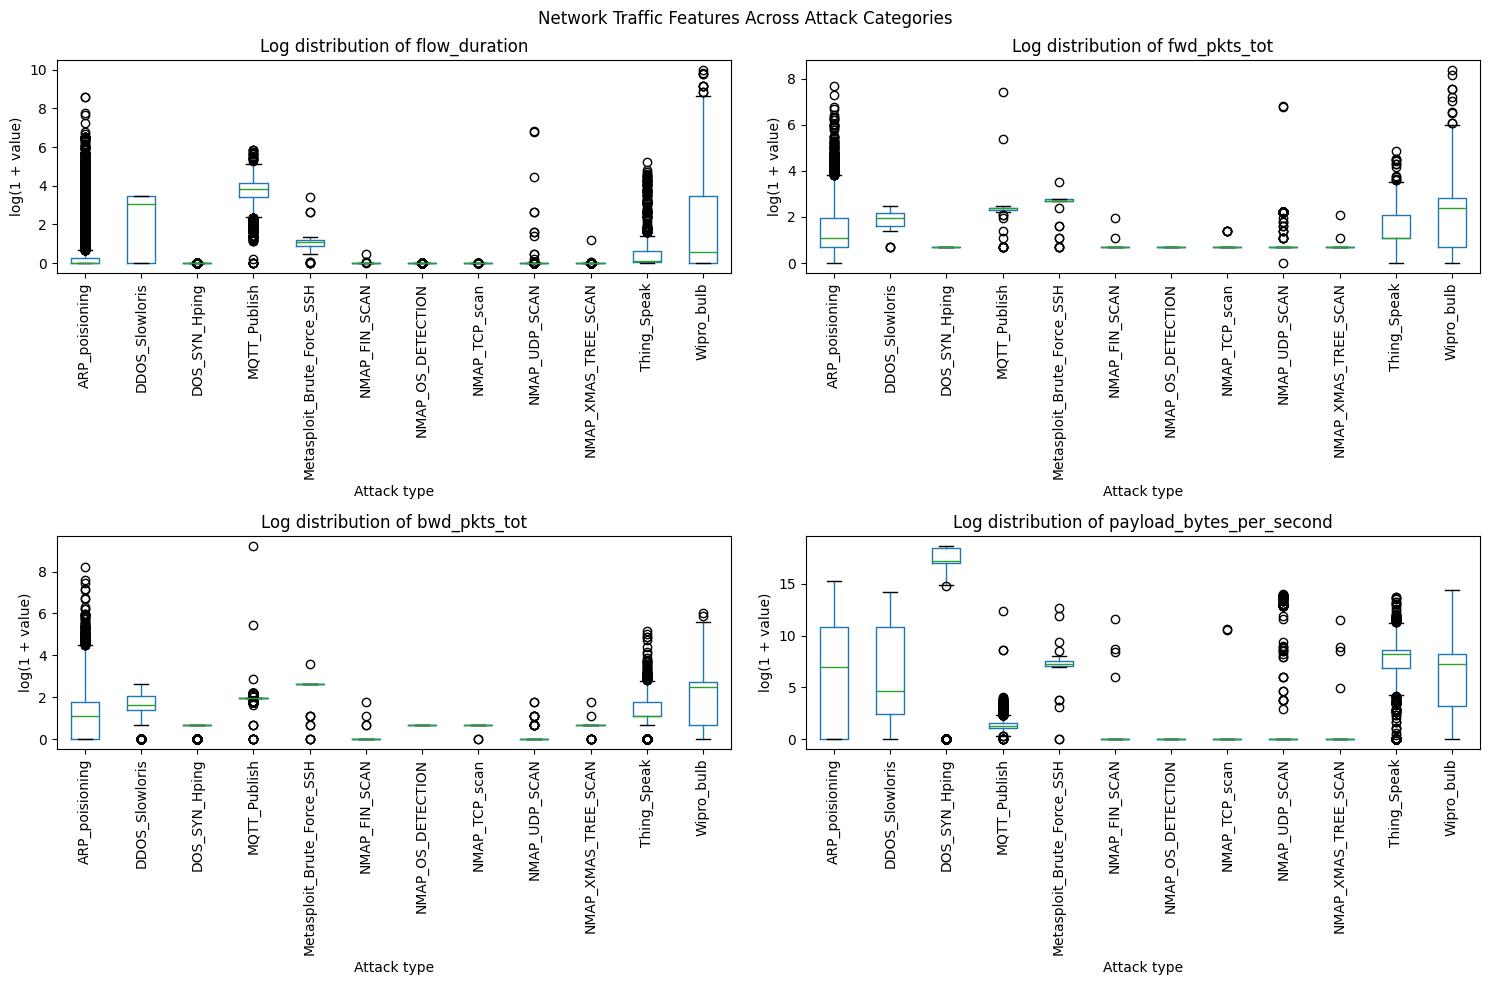

In [29]:
# Plotting the selected feature distributions by attack category

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, column in zip(axes.flatten(), selected_features):
    plot_data = df_eda[['Attack_type', column]].copy()
    plot_data[column] = np.log1p(plot_data[column])
    plot_data.boxplot(
        column=column,
        by='Attack_type',
        ax=ax,
        grid=False,
        rot=90
    )
    ax.set_title(f'Log distribution of {column}')
    ax.set_xlabel('Attack type')
    ax.set_ylabel('log(1 + value)')

fig.suptitle('Network Traffic Features Across Attack Categories')
plt.tight_layout()
plt.show()
plt.close(fig)

### EDA observations

- TCP is the most common protocol in this file, while the protocol mix differs across attack categories.
- The `service` column also has different distributions for different target classes. For example, MQTT_Publish is mostly associated with MQTT and DDOS_Slowloris is mostly associated with HTTP.
- Several numerical features have many zero values. These zeros can be meaningful for network measurements, so I have not removed those features just because of their zero percentage.
- Some features are highly skewed and some pairs are strongly correlated. I will keep the features for the baseline models and use scaling in the pipelines. I will not remove correlated features without a separate experiment.
- The class distribution is very uneven, so macro-averaged metrics will be important when comparing the models.

The plots and tables above are exploratory. The train/test split is made in the next section, and the preprocessing steps are fitted only on the training data.

## 8. Prepare the modelling dataset

In [30]:
# Removing the extra index and the constant feature from the modelling data

df_clean = df.drop(
    columns=['Unnamed: 0', 'bwd_URG_flag_count'],
    errors='ignore'
).copy()

X_all = df_clean.drop(columns=['Attack_type'])
y_all = df_clean['Attack_type']

print("Rows before resolving conflicting labels:", len(df_clean))
print("Input features:", X_all.shape[1])
print("Target classes:", y_all.nunique())

Rows before resolving conflicting labels: 123117
Input features: 82
Target classes: 12


In [31]:
# Finding identical input features that have been assigned different target labels

# The same feature combination is assigned one group ID.
feature_groups_all = X_all.groupby(
    X_all.columns.tolist(),
    dropna=False,
    sort=False
).ngroup()

group_label_counts = (
    pd.DataFrame({
        'group_id': feature_groups_all,
        'Attack_type': y_all.values
    })
    .groupby('group_id')['Attack_type']
    .nunique()
)

conflicting_group_ids = group_label_counts[group_label_counts > 1].index
conflicting_mask = feature_groups_all.isin(conflicting_group_ids)
df_conflicting = df_clean.loc[conflicting_mask].copy()

print("Conflicting feature groups:", len(conflicting_group_ids))
print("Records in those groups:", int(conflicting_mask.sum()))

Conflicting feature groups: 6
Records in those groups: 128


In [32]:
# Checking the labels found in each conflicting feature group

conflicting_report = (
    pd.DataFrame({
        'group_id': feature_groups_all[conflicting_mask],
        'Attack_type': y_all.loc[conflicting_mask].values
    })
    .groupby(['group_id', 'Attack_type'])
    .size()
    .reset_index(name='record_count')
)

display(conflicting_report)

,group_id,Attack_type,record_count
0,4200,ARP_poisioning,9
1,4200,DDOS_Slowloris,1
2,4200,Thing_Speak,65
3,4597,ARP_poisioning,17
4,4597,Thing_Speak,7
5,4975,ARP_poisioning,1
6,4975,Thing_Speak,3
7,4976,ARP_poisioning,1
8,4976,Thing_Speak,3
9,14484,ARP_poisioning,16


In [33]:
# Excluding the conflicting feature groups from the primary modelling dataset

# These records have the same input features but different target labels.
df_model = df_clean.loc[~conflicting_mask].copy()
X = df_model.drop(columns=['Attack_type'])
y = df_model['Attack_type']

print("Records retained:", len(df_model))
print("Records excluded:", int(conflicting_mask.sum()))
print("Input features:", X.shape[1])
print("Target classes:", y.nunique())

Records retained: 122989
Records excluded: 128
Input features: 82
Target classes: 12


In [34]:
# Creating group IDs for the remaining repeated feature combinations

groups = X.groupby(
    X.columns.tolist(),
    dropna=False,
    sort=False
).ngroup()

print("Unique feature groups:", groups.nunique())
print("Repeated rows after the first occurrence:", int(groups.duplicated().sum()))

Unique feature groups: 117909
Repeated rows after the first occurrence: 5080


In [35]:
# Checking that each remaining feature group has only one target label

group_label_check = pd.DataFrame({
    'group_id': groups,
    'Attack_type': y.values
})
remaining_conflicts = (
    group_label_check.groupby('group_id')['Attack_type'].nunique()
)
remaining_conflicts = remaining_conflicts[remaining_conflicts > 1]

print("Remaining conflicting groups:", len(remaining_conflicts))

Remaining conflicting groups: 0


## 9. Split the data into training and testing sets

The split is made at the feature-group level so identical input-feature combinations do not appear in both sets. `StratifiedGroupKFold` is used with five folds; the first fold is used as the holdout test set. The resulting split is close to 80:20, while keeping all 12 classes represented.

In [36]:
# Creating an approximately 80:20 split while keeping repeated feature groups together

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training percentage:", round(len(X_train) / len(X) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2))

Training records: 98428
Testing records: 24561
Training percentage: 80.03
Testing percentage: 19.97


In [37]:
# Checking that no feature group is shared between training and testing

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])
overlapping_groups = train_groups.intersection(test_groups)

print("Groups in training:", len(train_groups))
print("Groups in testing:", len(test_groups))
print("Overlapping groups:", len(overlapping_groups))

assert len(overlapping_groups) == 0, "A feature group appears in both sets."

Groups in training: 94326
Groups in testing: 23583
Overlapping groups: 0


In [38]:
# Comparing the target distribution in the original, training and testing data

class_comparison = pd.DataFrame({
    'Original': y.value_counts(),
    'Training': y_train.value_counts(),
    'Testing': y_test.value_counts()
}).fillna(0).astype(int)

for column in ['Original', 'Training', 'Testing']:
    class_comparison[column + '_%'] = (
        class_comparison[column] / class_comparison[column].sum() * 100
    ).round(2)

display(class_comparison.sort_values('Original', ascending=False))

,Original,Training,Testing,Original_%,Training_%,Testing_%
Attack_type,,,,,,
DOS_SYN_Hping,94659,75765,18894,76.97,76.98,76.93
Thing_Speak,8030,6421,1609,6.53,6.52,6.55
ARP_poisioning,7706,6166,1540,6.27,6.26,6.27
MQTT_Publish,4146,3315,831,3.37,3.37,3.38
NMAP_UDP_SCAN,2587,2067,520,2.10,2.10,2.12
NMAP_XMAS_TREE_SCAN,2010,1608,402,1.63,1.63,1.64
NMAP_OS_DETECTION,2000,1600,400,1.63,1.63,1.63
NMAP_TCP_scan,1002,803,199,0.81,0.82,0.81
DDOS_Slowloris,533,428,105,0.43,0.43,0.43


In [39]:
# Checking that all target classes are represented in both datasets

missing_train_classes = set(y.unique()) - set(y_train.unique())
missing_test_classes = set(y.unique()) - set(y_test.unique())

print("Classes in original data:", y.nunique())
print("Classes in training data:", y_train.nunique())
print("Classes in testing data:", y_test.nunique())
print("Classes missing from training:", missing_train_classes)
print("Classes missing from testing:", missing_test_classes)

assert not missing_train_classes
assert not missing_test_classes

Classes in original data: 12
Classes in training data: 12
Classes in testing data: 12
Classes missing from training: set()
Classes missing from testing: set()


### Training and testing split

The conflicting groups were excluded from the primary experiment because their input features are identical but their target labels differ. The remaining data was split using `StratifiedGroupKFold`.

The group check shows that identical feature combinations are kept together. I also checked the class counts in both sets because the two smallest attack categories have very few records. Their class-wise scores will need to be interpreted carefully.

In [40]:
# Adding the target column back so both CSV files can be used for evaluation later

train_data = X_train.copy()
train_data['Attack_type'] = y_train

test_data = X_test.copy()
test_data['Attack_type'] = y_test

print("Training CSV shape:", train_data.shape)
print("Testing CSV shape:", test_data.shape)

Training CSV shape: (98428, 83)
Testing CSV shape: (24561, 83)


In [41]:
# Saving the training and testing files separately

TRAIN_PATH = SPLIT_DIR / "train_data.csv"
TEST_PATH = SPLIT_DIR / "test_data.csv"

train_data.to_csv(TRAIN_PATH, index=False)
test_data.to_csv(TEST_PATH, index=False)

print("Training data saved to:", TRAIN_PATH)
print("Testing data saved to:", TEST_PATH)

Training data saved to: /home/s2026aj05664/workspace/Munnawar/Machine Learning/splits/train_data.csv
Testing data saved to: /home/s2026aj05664/workspace/Munnawar/Machine Learning/splits/test_data.csv


In [42]:
# Loading the saved CSV files again before starting model training

train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

X_train = train_data.drop(columns=['Attack_type'])
y_train = train_data['Attack_type']
X_test = test_data.drop(columns=['Attack_type'])
y_test = test_data['Attack_type']

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Target column in test file:", 'Attack_type' in test_data.columns)

Training data: (98428, 82)
Testing data: (24561, 82)
Target column in test file: True


In [43]:
# Checking the feature types that will be passed into the preprocessing pipeline

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Categorical columns:", categorical_features)

Numerical features: 80
Categorical features: 2
Categorical columns: ['proto', 'service']


## 10. Set up preprocessing and evaluation

In [44]:
# Building the preprocessing steps used by each model

def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('numerical', StandardScaler(), numeric_features),
            ('categorical', OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ), categorical_features)
        ],
        remainder='drop'
    )

print("Preprocessing function is ready.")

Preprocessing function is ready.


In [45]:
# Creating one function to calculate the six metrics for each classifier

def evaluate_model(model_name, model, y_true, y_pred, scores, score_type='probability'):
    class_order = model.named_steps['classifier'].classes_

    if score_type == 'probability':
        # Probability-based AUC for Logistic Regression, Decision Tree, KNN and Naive Bayes
        auc_value = roc_auc_score(
            y_true,
            scores,
            labels=class_order,
            multi_class='ovr',
            average='macro'
        )
    elif score_type == 'decision':
        # For Linear SVM, calculate one-vs-rest AUC from each class decision score
        class_auc = []
        for column_index, class_name in enumerate(class_order):
            binary_target = (y_true == class_name).astype(int)
            class_auc.append(
                roc_auc_score(binary_target, scores[:, column_index])
            )
        auc_value = float(np.mean(class_auc))
    else:
        raise ValueError("score_type must be 'probability' or 'decision'.")

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'AUC': auc_value,
        'Precision': precision_score(
            y_true, y_pred, labels=class_order, average='macro', zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, labels=class_order, average='macro', zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, labels=class_order, average='macro', zero_division=0
        ),
        'MCC': matthews_corrcoef(y_true, y_pred)
    }


def add_model_result(metrics):
    # Replacing a previous entry makes this cell safe to run again during testing.
    model_results[:] = [
        row for row in model_results if row['Model'] != metrics['Model']
    ]
    model_results.append(metrics)


def show_classification_report(y_true, y_pred, model_name):
    print(f"Classification report – {model_name}\n")
    print(classification_report(y_true, y_pred, zero_division=0))

model_results = []
print("Evaluation functions are ready.")

Evaluation functions are ready.


## 11. Model 1 – Logistic Regression

In [46]:
# Setting up Logistic Regression with the common preprocessing steps

logistic_model = Pipeline(
    steps=[
        ('preprocessor', create_preprocessor()),
        ('classifier', LogisticRegression(
            max_iter=1000,
            solver='lbfgs',
            random_state=42
        ))
    ]
)

print("Logistic Regression model configured.")

Logistic Regression model configured.


In [47]:
# Fitting Logistic Regression on the training data

print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)
print("Training completed.")

Training Logistic Regression...
Training completed.


In [48]:
# Predicting the attack categories in the test data

y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)

print("Predictions generated.")
print("Actual labels:", y_test.head().tolist())
print("Predicted labels:", y_pred_logistic[:5])

Predictions generated.
Actual labels: ['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']
Predicted labels: ['MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish'
 'MQTT_Publish']


In [49]:
# Calculating the evaluation metrics for Logistic Regression

logistic_metrics = evaluate_model(
    'Logistic Regression',
    logistic_model,
    y_test,
    y_pred_logistic,
    y_prob_logistic,
    score_type='probability'
)
add_model_result(logistic_metrics)

display(pd.DataFrame([logistic_metrics]).set_index('Model').round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.9921,0.9867,0.9712,0.9328,0.9503,0.9802


In [50]:
# Checking the results for each attack category

show_classification_report(y_test, y_pred_logistic, 'Logistic Regression')

Classification report – Logistic Regression

                            precision    recall  f1-score   support

            ARP_poisioning       0.95      0.95      0.95      1540
            DDOS_Slowloris       0.98      0.81      0.89       105
             DOS_SYN_Hping       1.00      1.00      1.00     18894
              MQTT_Publish       1.00      1.00      1.00       831
Metasploit_Brute_Force_SSH       1.00      0.86      0.92         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       0.99      1.00      1.00       199
             NMAP_UDP_SCAN       0.96      0.98      0.97       520
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.95      0.96      0.95      1609
                Wipro_bulb       0.83      0.81      0.82        48

                  accuracy                           0.99     24561
 

### Logistic Regression – observation

Logistic Regression achieved **99.19% accuracy** and **98.53% macro AUC** in the recorded baseline run. Its macro precision, recall and F1-score were 95.70%, 93.07% and 94.27%.

It performed well for most attack categories, but recall was lower for DDOS_Slowloris and Wipro_bulb. The difference between macro and weighted results also shows why accuracy alone is not enough for this imbalanced dataset.

## 12. Model 2 – Decision Tree Classifier

In [51]:
# Setting up the Decision Tree classifier

decision_tree_model = Pipeline(
    steps=[
        ('preprocessor', create_preprocessor()),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ]
)

print("Decision Tree model configured.")

Decision Tree model configured.


In [52]:
# Fitting the Decision Tree on the training data

print("Training Decision Tree...")
decision_tree_model.fit(X_train, y_train)
print("Training completed.")

Training Decision Tree...
Training completed.


In [53]:
# Predicting the attack categories and class probabilities

y_pred_tree = decision_tree_model.predict(X_test)
y_prob_tree = decision_tree_model.predict_proba(X_test)

print("Predictions generated.")
print("Actual labels:", y_test.head().tolist())
print("Predicted labels:", y_pred_tree[:5])

Predictions generated.
Actual labels: ['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']
Predicted labels: ['MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish'
 'MQTT_Publish']


In [54]:
# Calculating the evaluation metrics for Decision Tree

tree_metrics = evaluate_model(
    'Decision Tree',
    decision_tree_model,
    y_test,
    y_pred_tree,
    y_prob_tree,
    score_type='probability'
)
add_model_result(tree_metrics)

display(pd.DataFrame([tree_metrics]).set_index('Model').round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Decision Tree,0.998,0.982,0.9908,0.9641,0.9763,0.9949


In [55]:
# Checking the results for each attack category

show_classification_report(y_test, y_pred_tree, 'Decision Tree')

Classification report – Decision Tree

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1540
            DDOS_Slowloris       0.99      1.00      1.00       105
             DOS_SYN_Hping       1.00      1.00      1.00     18894
              MQTT_Publish       1.00      1.00      1.00       831
Metasploit_Brute_Force_SSH       1.00      0.86      0.92         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       199
             NMAP_UDP_SCAN       0.99      0.99      0.99       520
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1609
                Wipro_bulb       0.94      0.92      0.93        48

                  accuracy                           1.00     24561
       

In [56]:
# Comparing Decision Tree performance on the training and testing data

tree_train_pred = decision_tree_model.predict(X_train)

tree_overfit_results = pd.DataFrame([{
    'Training Accuracy': accuracy_score(y_train, tree_train_pred),
    'Testing Accuracy': accuracy_score(y_test, y_pred_tree),
    'Training Macro F1': f1_score(y_train, tree_train_pred, average='macro', zero_division=0),
    'Testing Macro F1': f1_score(y_test, y_pred_tree, average='macro', zero_division=0),
    'Tree Depth': decision_tree_model.named_steps['classifier'].get_depth(),
    'Number of Leaves': decision_tree_model.named_steps['classifier'].get_n_leaves()
}])

display(tree_overfit_results.round(4))

,Training Accuracy,Testing Accuracy,Training Macro F1,Testing Macro F1,Tree Depth,Number of Leaves
0,1.0,0.998,1.0,0.9763,22,220


### Decision Tree – observation

In the recorded baseline run, the Decision Tree achieved **99.80% accuracy** and a **97.63% macro F1-score**. It had the strongest accuracy, precision, F1-score and MCC among the five initial models.

The tree achieved perfect scores on the training data, while the test accuracy was 99.80%. This is a small accuracy gap, although the macro F1 gap is larger. I have kept this unrestricted tree as the baseline rather than changing its settings after looking at the test results.

## 13. Model 3 – K-Nearest Neighbors (KNN)

In [57]:
# Setting up KNN with distance-based weighting

knn_model = Pipeline(
    steps=[
        ('preprocessor', create_preprocessor()),
        ('classifier', KNeighborsClassifier(
            n_neighbors=5,
            weights='distance',
            metric='euclidean',
            n_jobs=-1
        ))
    ]
)

print("KNN model configured.")

KNN model configured.


In [58]:
# Fitting KNN on the training data

print("Training KNN...")
knn_model.fit(X_train, y_train)
print("Training completed.")

Training KNN...
Training completed.


In [59]:
# Predicting attack categories and class probabilities with KNN

y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)

print("Predictions generated.")
print("Actual labels:", y_test.head().tolist())
print("Predicted labels:", y_pred_knn[:5])

Predictions generated.
Actual labels: ['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']
Predicted labels: ['MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish'
 'MQTT_Publish']


In [60]:
# Calculating the evaluation metrics for KNN

knn_metrics = evaluate_model(
    'KNN',
    knn_model,
    y_test,
    y_pred_knn,
    y_prob_knn,
    score_type='probability'
)
add_model_result(knn_metrics)

display(pd.DataFrame([knn_metrics]).set_index('Model').round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
KNN,0.9974,0.9845,0.9857,0.9644,0.9739,0.9935


In [61]:
# Checking the results for each attack category

show_classification_report(y_test, y_pred_knn, 'KNN')

Classification report – KNN

                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.98      1540
            DDOS_Slowloris       0.99      0.99      0.99       105
             DOS_SYN_Hping       1.00      1.00      1.00     18894
              MQTT_Publish       1.00      1.00      1.00       831
Metasploit_Brute_Force_SSH       1.00      0.86      0.92         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       199
             NMAP_UDP_SCAN       0.99      0.99      0.99       520
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.98      0.98      1609
                Wipro_bulb       0.88      0.94      0.91        48

                  accuracy                           1.00     24561
                 

### KNN – observation

KNN achieved **99.74% accuracy** and a **97.39% macro F1-score** in the recorded baseline run. It had the highest macro recall among the five models, although it was slightly behind Decision Tree in accuracy, precision, F1-score and MCC.

It performed well across most attack categories. Its prediction step is more computationally demanding because it compares test observations with the training data.

## 14. Model 4 – Gaussian Naive Bayes

In [62]:
# Setting up Gaussian Naive Bayes

naive_bayes_model = Pipeline(
    steps=[
        ('preprocessor', create_preprocessor()),
        ('classifier', GaussianNB())
    ]
)

print("Gaussian Naive Bayes model configured.")

Gaussian Naive Bayes model configured.


In [63]:
# Fitting Gaussian Naive Bayes on the training data

print("Training Gaussian Naive Bayes...")
naive_bayes_model.fit(X_train, y_train)
print("Training completed.")

Training Gaussian Naive Bayes...
Training completed.


In [64]:
# Predicting attack categories and class probabilities with Naive Bayes

y_pred_nb = naive_bayes_model.predict(X_test)
y_prob_nb = naive_bayes_model.predict_proba(X_test)

print("Predictions generated.")
print("Actual labels:", y_test.head().tolist())
print("Predicted labels:", y_pred_nb[:5])

Predictions generated.
Actual labels: ['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']
Predicted labels: ['MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish'
 'MQTT_Publish']


In [65]:
# Calculating the evaluation metrics for Gaussian Naive Bayes

nb_metrics = evaluate_model(
    'Naive Bayes',
    naive_bayes_model,
    y_test,
    y_pred_nb,
    y_prob_nb,
    score_type='probability'
)
add_model_result(nb_metrics)

display(pd.DataFrame([nb_metrics]).set_index('Model').round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Naive Bayes,0.9007,0.9773,0.6332,0.7859,0.5889,0.7593


In [66]:
# Checking the results for each attack category

show_classification_report(y_test, y_pred_nb, 'Gaussian Naive Bayes')

Classification report – Gaussian Naive Bayes

                            precision    recall  f1-score   support

            ARP_poisioning       0.97      0.35      0.52      1540
            DDOS_Slowloris       0.15      0.99      0.26       105
             DOS_SYN_Hping       1.00      1.00      1.00     18894
              MQTT_Publish       1.00      1.00      1.00       831
Metasploit_Brute_Force_SSH       0.01      0.86      0.02         7
             NMAP_FIN_SCAN       0.01      0.83      0.01         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      0.99      1.00       199
             NMAP_UDP_SCAN       0.54      0.89      0.67       520
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.61      0.16      0.26      1609
                Wipro_bulb       0.30      0.35      0.33        48

                  accuracy                           0.90     24561


In [67]:
# Comparing the actual and predicted number of records in each class

nb_prediction_comparison = pd.DataFrame({
    'Actual_Count': y_test.value_counts(),
    'Predicted_Count': pd.Series(y_pred_nb).value_counts()
}).fillna(0).astype(int)

nb_prediction_comparison['Difference'] = (
    nb_prediction_comparison['Predicted_Count'] - nb_prediction_comparison['Actual_Count']
)

display(nb_prediction_comparison.sort_values('Difference', ascending=False))

,Actual_Count,Predicted_Count,Difference
NMAP_FIN_SCAN,6,688,682
DDOS_Slowloris,105,697,592
Metasploit_Brute_Force_SSH,7,557,550
NMAP_UDP_SCAN,520,852,332
Wipro_bulb,48,56,8
NMAP_OS_DETECTION,400,400,0
DOS_SYN_Hping,18894,18894,0
NMAP_TCP_scan,199,198,-1
NMAP_XMAS_TREE_SCAN,402,401,-1
MQTT_Publish,831,829,-2


### Gaussian Naive Bayes – observation

Gaussian Naive Bayes achieved **90.07% accuracy** and a **58.89% macro F1-score** in the recorded baseline run. Its AUC was still relatively high at 97.73%, but its precision and class-wise predictions were weaker than the other models.

The result may be related to the assumptions made by Gaussian Naive Bayes. The EDA showed highly skewed features and several strongly correlated feature pairs, while the model assumes conditional independence and Gaussian feature distributions within each class. This is a possible explanation, not proof of the cause.

## 15. Model 5 – Support Vector Machine

For this dataset, I used a linear SVM implemented through `SGDClassifier` with hinge loss. The earlier `LinearSVC` attempt took much longer and did not converge within the selected iteration limit, so the final baseline uses the SGD-based linear SVM implementation.

In [68]:
# Setting up a linear SVM using hinge loss and stochastic gradient descent

svm_model = Pipeline(
    steps=[
        ('preprocessor', create_preprocessor()),
        ('classifier', SGDClassifier(
            loss='hinge',
            penalty='l2',
            alpha=0.0001,
            max_iter=2000,
            tol=1e-3,
            random_state=42,
            n_jobs=-1,
            average=True
        ))
    ]
)

print("Linear SVM model configured.")

Linear SVM model configured.


In [69]:
# Training the SVM and checking whether it converges

start_time = time.time()

with warnings.catch_warnings(record=True) as svm_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    svm_model.fit(X_train, y_train)

svm_training_time = time.time() - start_time
svm_classifier = svm_model.named_steps['classifier']
convergence_warnings = [
    warning for warning in svm_warnings
    if issubclass(warning.category, ConvergenceWarning)
]

print("Training time:", round(svm_training_time, 2), "seconds")
print("Iterations used:", svm_classifier.n_iter_)
print("Convergence warnings:", len(convergence_warnings))

for warning in convergence_warnings:
    print(warning.message)

Training time: 4.06 seconds
Iterations used: 26
Convergence warnings: 0


In [70]:
# Generating SVM predictions and decision scores

y_pred_svm = svm_model.predict(X_test)
y_scores_svm = svm_model.decision_function(X_test)

print("Predictions generated.")
print("Actual labels:", y_test.head().tolist())
print("Predicted labels:", y_pred_svm[:5])
print("Decision score shape:", y_scores_svm.shape)

Predictions generated.
Actual labels: ['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']
Predicted labels: ['MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish' 'MQTT_Publish'
 'MQTT_Publish']
Decision score shape: (24561, 12)


In [71]:
# Calculating the evaluation metrics for the SVM

svm_metrics = evaluate_model(
    'Support Vector Machine',
    svm_model,
    y_test,
    y_pred_svm,
    y_scores_svm,
    score_type='decision'
)
add_model_result(svm_metrics)

display(pd.DataFrame([svm_metrics]).set_index('Model').round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Support Vector Machine,0.9822,0.9801,0.7942,0.7378,0.7574,0.9553


In [72]:
# Checking the SVM results for each attack category

show_classification_report(y_test, y_pred_svm, 'Support Vector Machine')

Classification report – Support Vector Machine

                            precision    recall  f1-score   support

            ARP_poisioning       0.88      0.86      0.87      1540
            DDOS_Slowloris       0.93      0.65      0.76       105
             DOS_SYN_Hping       1.00      1.00      1.00     18894
              MQTT_Publish       1.00      1.00      1.00       831
Metasploit_Brute_Force_SSH       0.00      0.00      0.00         7
             NMAP_FIN_SCAN       0.00      0.00      0.00         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       0.99      0.99      0.99       199
             NMAP_UDP_SCAN       0.94      0.98      0.96       520
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.88      0.92      0.90      1609
                Wipro_bulb       0.92      0.46      0.61        48

                  accuracy                           0.98     2456

### Support Vector Machine – observation

The linear SVM using hinge loss completed training in **6.24 seconds** in the recorded baseline run, with no convergence warnings. It achieved **98.22% accuracy** and a **75.74% macro F1-score**.

The model performed well for several of the larger attack categories, but it did not identify the two rarest categories in the recorded test run. This is reflected in the lower macro precision, recall and F1-score. Its AUC was calculated from the class decision scores using a one-vs-rest calculation for each class.

## 16. Compare the five models

In [73]:
# Preparing the comparison table in the same order as the assignment

model_order = [
    'Logistic Regression',
    'Decision Tree',
    'KNN',
    'Naive Bayes',
    'Support Vector Machine'
]

results_df = pd.DataFrame(model_results)
results_df['Model'] = pd.Categorical(
    results_df['Model'], categories=model_order, ordered=True
)
results_df = results_df.sort_values('Model').reset_index(drop=True)

# Showing the six metrics required in the assignment
display(results_df.set_index('Model').round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.9921,0.9867,0.9712,0.9328,0.9503,0.9802
Decision Tree,0.9980,0.9820,0.9908,0.9641,0.9763,0.9949
KNN,0.9974,0.9845,0.9857,0.9644,0.9739,0.9935
Naive Bayes,0.9007,0.9773,0.6332,0.7859,0.5889,0.7593
Support Vector Machine,0.9822,0.9801,0.7942,0.7378,0.7574,0.9553


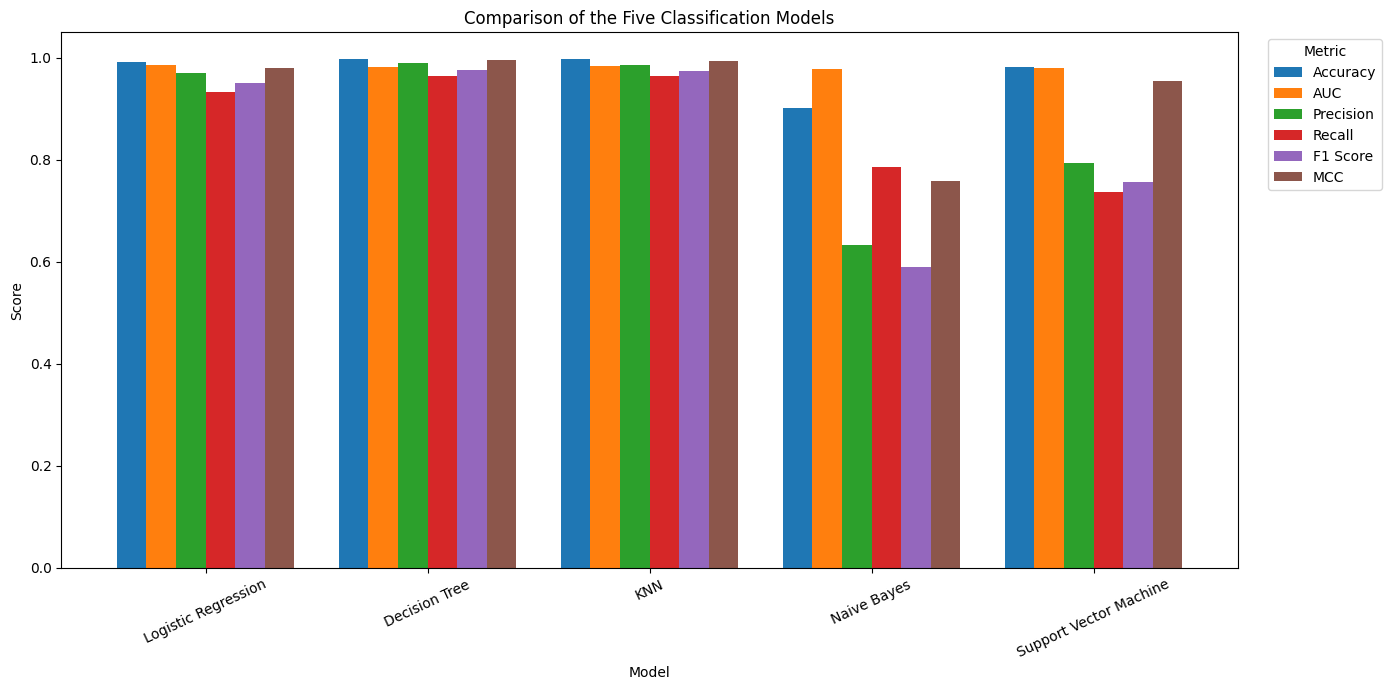

In [74]:
# Plotting the main metrics side by side for a quick comparison

metrics_to_plot = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score', 'MCC']
plot_results = results_df.set_index('Model')[metrics_to_plot]

ax = plot_results.plot(kind='bar', figsize=(14, 7), width=0.8)
ax.set_title('Comparison of the Five Classification Models')
ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=25)
ax.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.close()

### Comparison observations

In the recorded baseline run, Decision Tree had the highest accuracy (99.80%), macro precision (99.08%), macro F1-score (97.63%) and MCC (99.49%). KNN had the highest macro recall (96.44%), while Logistic Regression had the highest macro AUC (98.53%).

Naive Bayes had the weakest macro F1-score, and the linear SVM struggled with the two smallest test classes. Based on the six metrics together, Decision Tree is the strongest baseline on this test split. This is a result for this dataset and split, not a claim that it will always be the best model on other network traffic data.

## 17. Confusion matrices

In [75]:
# Keeping the predictions together so the same plotting code can be used for each model

model_predictions = {
    'Logistic Regression': y_pred_logistic,
    'Decision Tree': y_pred_tree,
    'KNN': y_pred_knn,
    'Naive Bayes': y_pred_nb,
    'Support Vector Machine': y_pred_svm
}

class_labels = sorted(y_test.unique())
print("Number of classes:", len(class_labels))

Number of classes: 12


In [76]:
# Function to display and optionally save a normalised confusion matrix

def plot_confusion_matrix(
    model_name,
    y_true,
    y_pred,
    class_labels,
    save_path=None,
    show=True
):
    fig, ax = plt.subplots(figsize=(15, 11))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=class_labels,
        normalize='true',
        cmap='Blues',
        values_format='.2f',
        xticks_rotation=45,
        ax=ax,
        colorbar=True
    )

    ax.set_title(
        f'{model_name} - Normalised Confusion Matrix',
        fontsize=16,
        pad=20
    )
    ax.set_xlabel('Predicted Attack Type', fontsize=12)
    ax.set_ylabel('Actual Attack Type', fontsize=12)
    ax.tick_params(axis='both', labelsize=9)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=200, bbox_inches='tight')

    if show:
        plt.show()

    plt.close(fig)

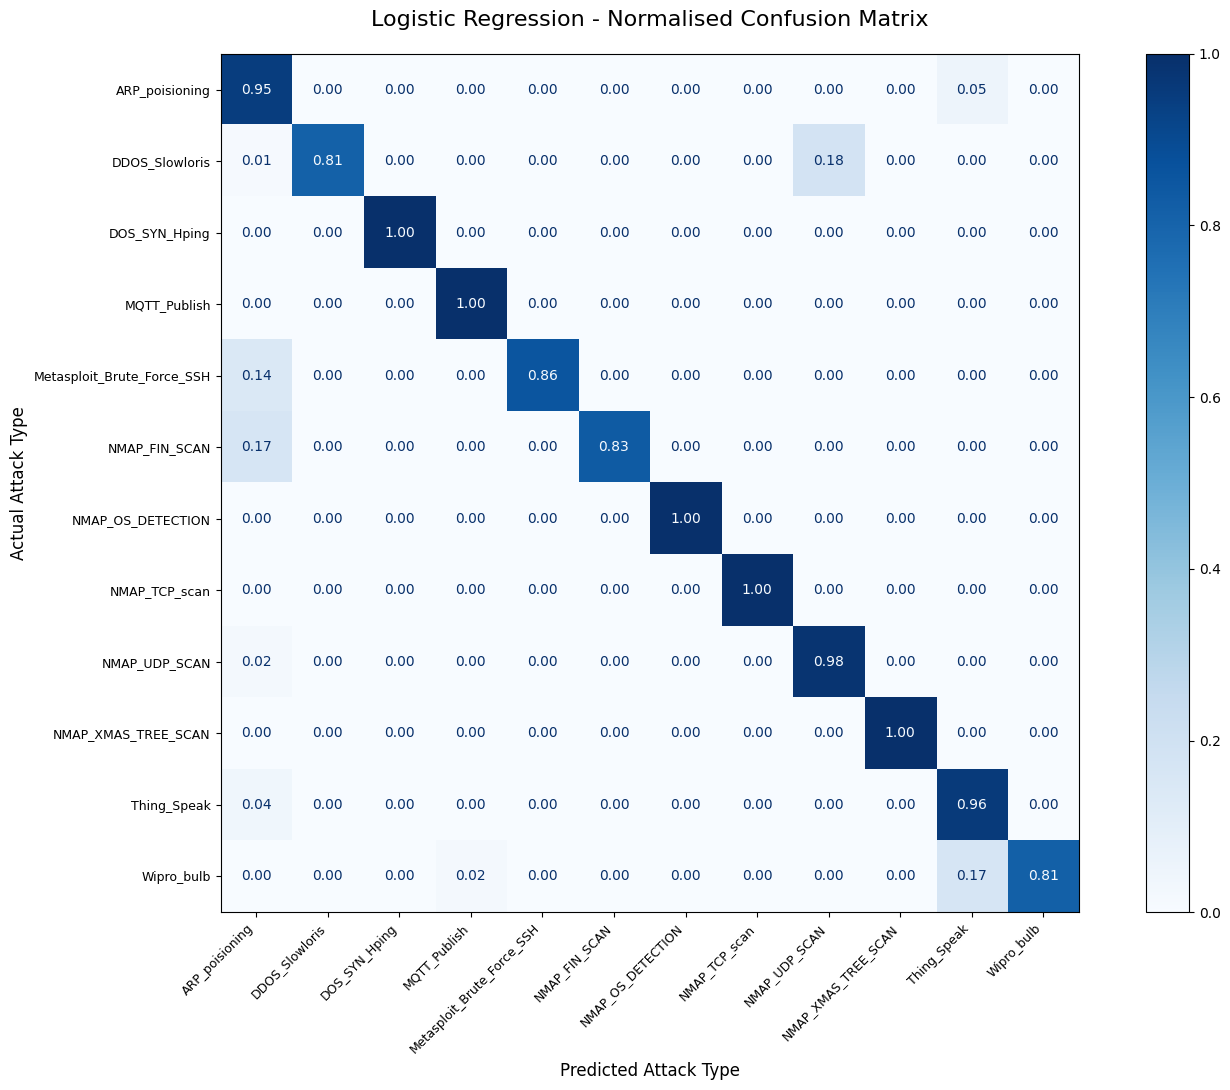

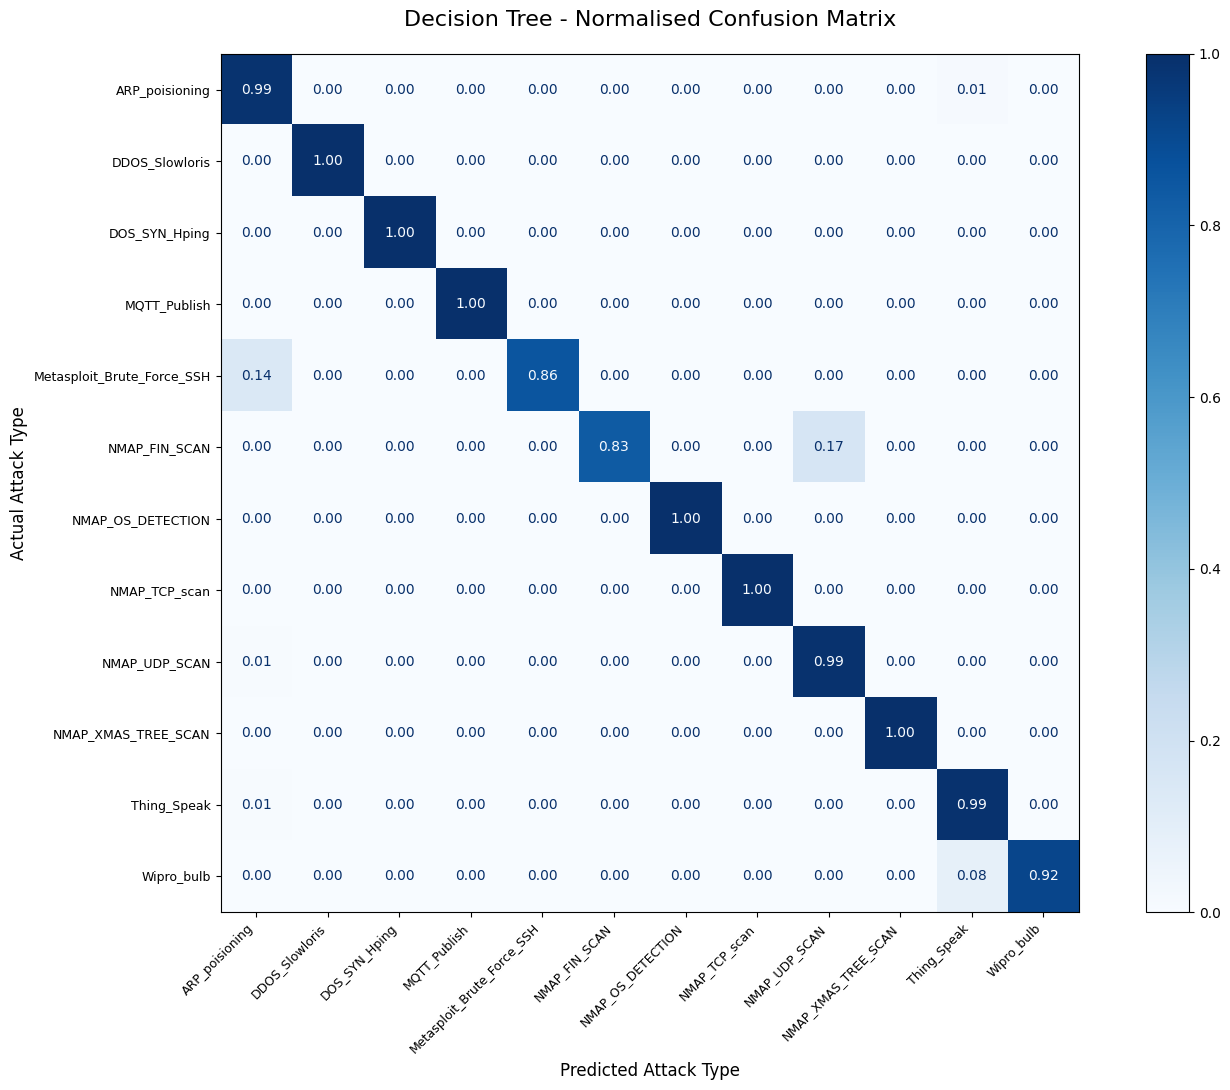

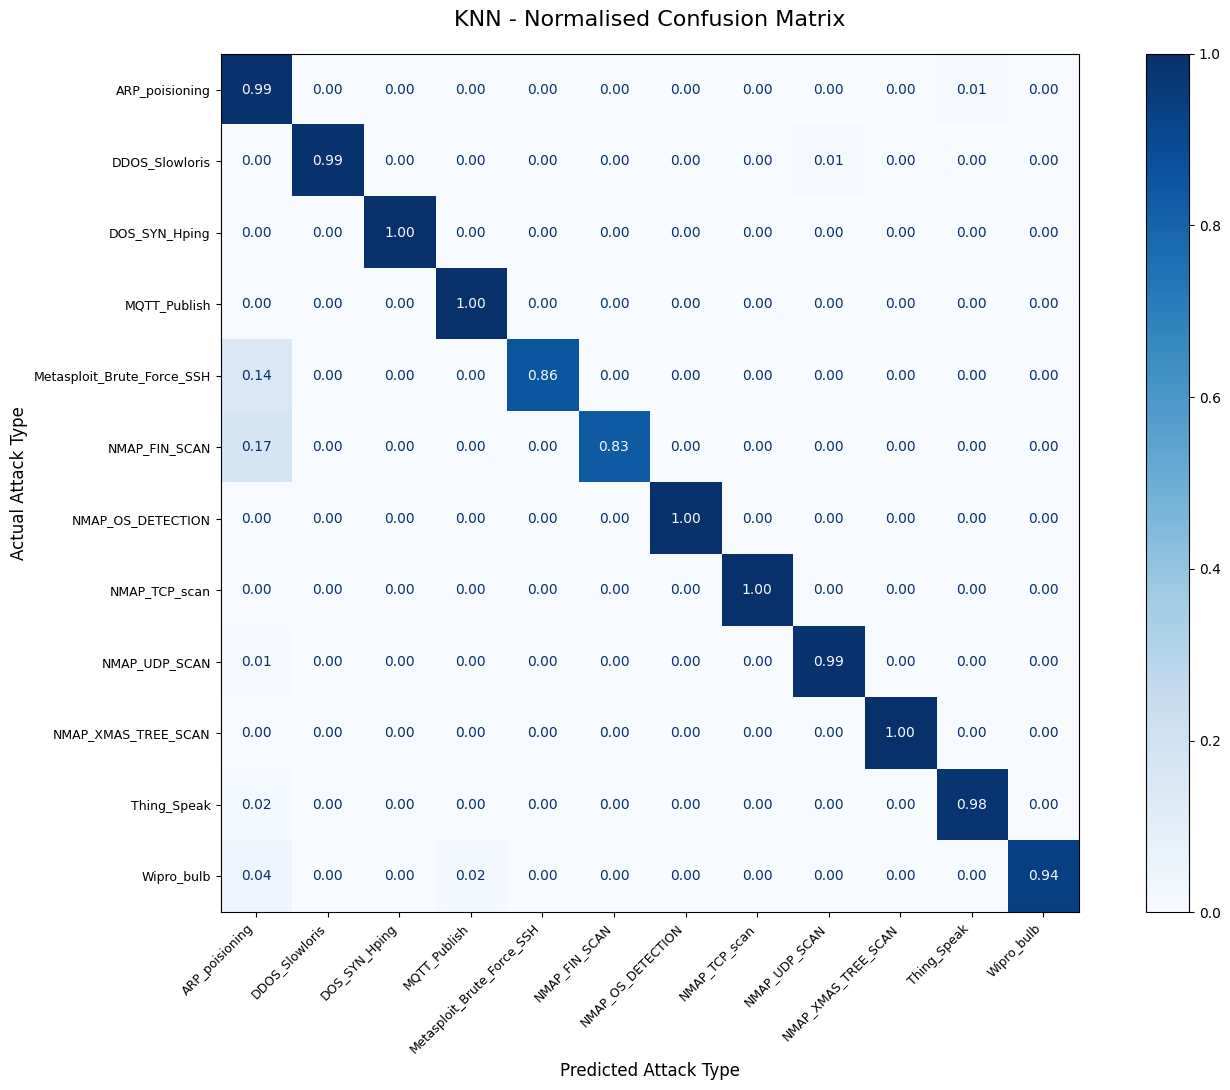

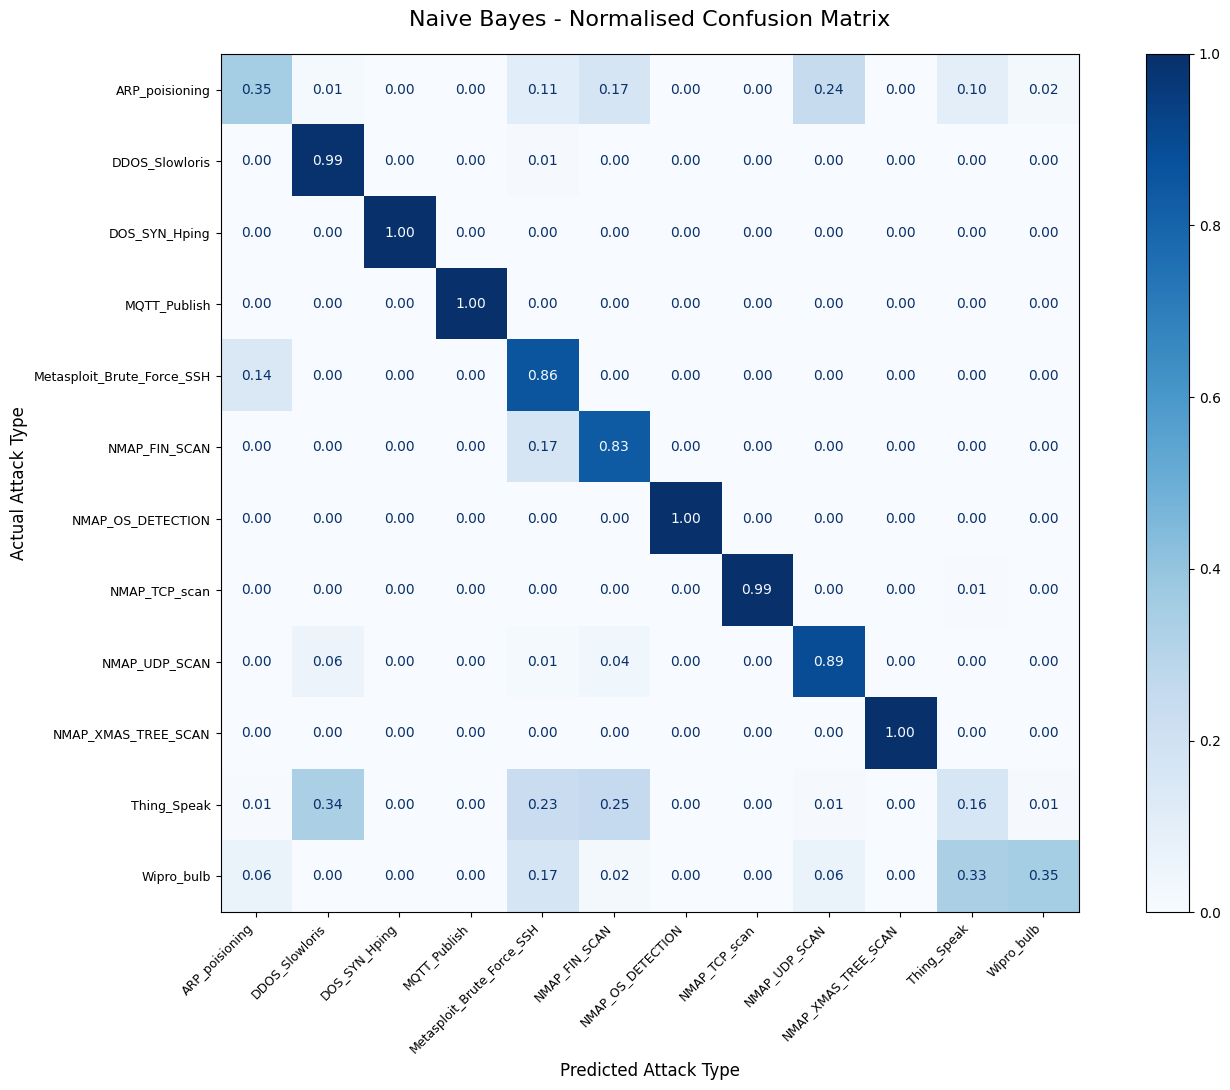

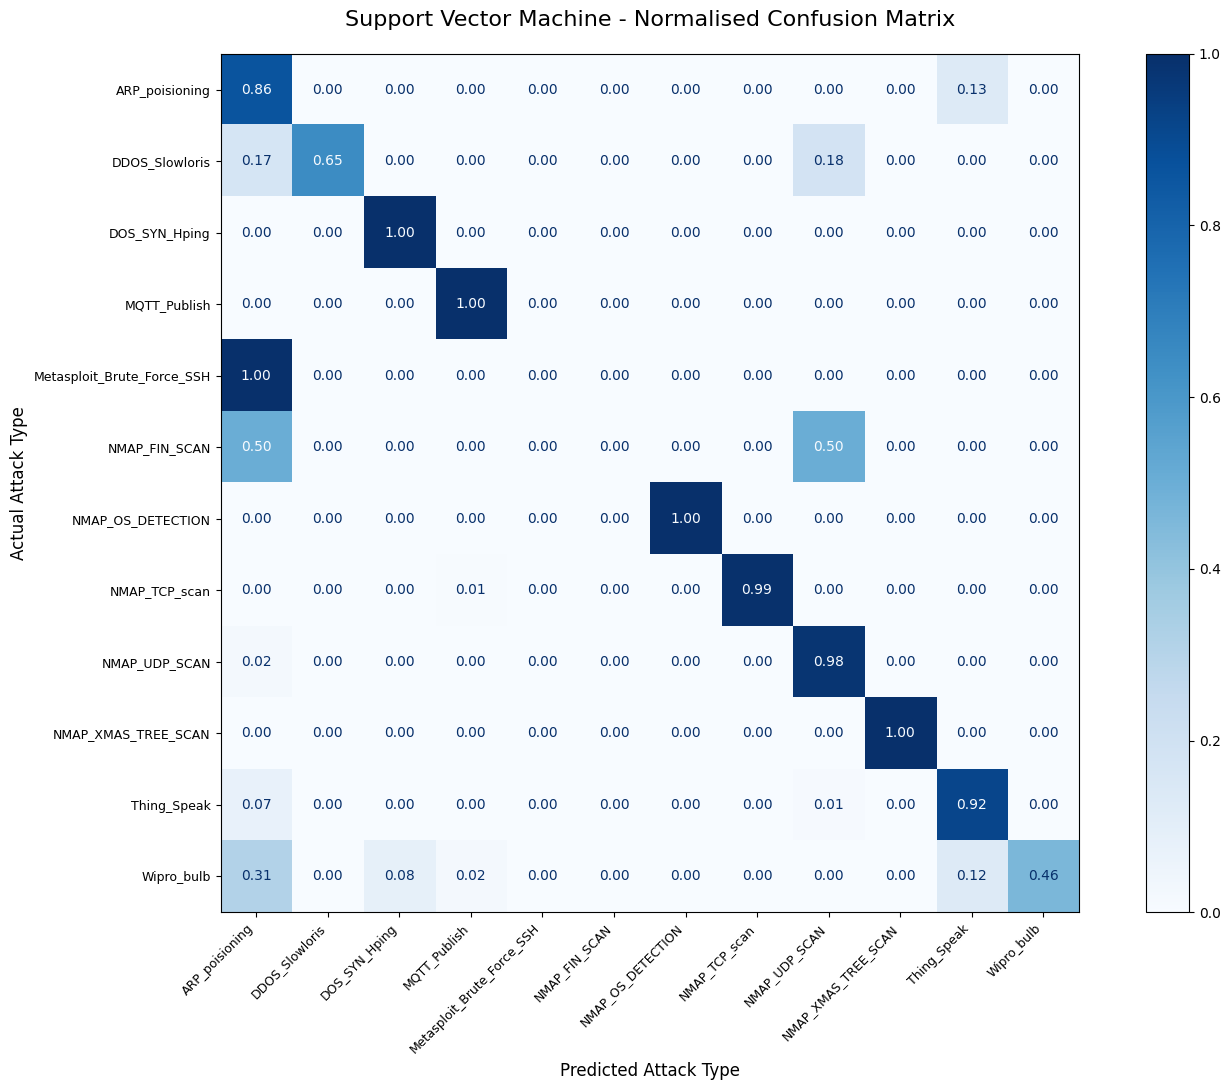

In [77]:
# Displaying the normalised confusion matrices for all five models

for model_name, predictions in model_predictions.items():
    plot_confusion_matrix(
        model_name=model_name,
        y_true=y_test,
        y_pred=predictions,
        class_labels=class_labels
    )

## 18. Save the models and evaluation files

In [78]:
# Collecting the five fitted pipelines in one dictionary

trained_models = {
    'logistic_regression': logistic_model,
    'decision_tree': decision_tree_model,
    'knn': knn_model,
    'naive_bayes': naive_bayes_model,
    'svm': svm_model
}

# Saving each complete pipeline, including its fitted preprocessing steps
for model_name, model in trained_models.items():
    model_path = MODEL_DIR / f"{model_name}.joblib"
    joblib.dump(model, model_path, compress=3)
    print(f"Saved: {model_path.name}")

print("All five model pipelines saved.")

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib
All five model pipelines saved.


In [79]:
# Loading the saved pipelines and checking that they still make the same predictions

loaded_models = {}
original_predictions = {
    'logistic_regression': y_pred_logistic,
    'decision_tree': y_pred_tree,
    'knn': y_pred_knn,
    'naive_bayes': y_pred_nb,
    'svm': y_pred_svm
}

for model_name in trained_models:
    model_path = MODEL_DIR / f"{model_name}.joblib"
    loaded_models[model_name] = joblib.load(model_path)

    saved_predictions = loaded_models[model_name].predict(X_test)
    matches = np.array_equal(saved_predictions, original_predictions[model_name])
    print(f"{model_name}: {'Verified' if matches else 'Mismatch'}")

    assert matches, f"Predictions changed after loading {model_name}."

logistic_regression: Verified
decision_tree: Verified
knn: Verified
naive_bayes: Verified
svm: Verified


In [80]:
# Saving the confusion matrices, classification reports and comparison table

for model_name, predictions in model_predictions.items():
    file_name = model_name.lower().replace(' ', '_')

    # Saving the confusion matrix as record counts
    cm = confusion_matrix(y_test, predictions, labels=class_labels)
    pd.DataFrame(cm, index=class_labels, columns=class_labels).to_csv(
        CM_DIR / f"{file_name}_confusion_matrix.csv"
    )

    # Saving the row-normalised confusion matrix
    cm_normalised = confusion_matrix(
        y_test, predictions, labels=class_labels, normalize='true'
    )
    pd.DataFrame(
        cm_normalised, index=class_labels, columns=class_labels
    ).to_csv(CM_DIR / f"{file_name}_normalised_confusion_matrix.csv")

    # Saving the classification report for each model
    report = classification_report(
        y_test,
        predictions,
        labels=class_labels,
        output_dict=True,
        zero_division=0
    )
    pd.DataFrame(report).T.to_csv(
        REPORT_DIR / f"{file_name}_classification_report.csv"
    )

    # Saving the same large-format confusion matrix shown above
    plot_confusion_matrix(
        model_name=model_name,
        y_true=y_test,
        y_pred=predictions,
        class_labels=class_labels,
        save_path=CM_DIR / f"{file_name}_confusion_matrix.png",
        show=False
    )

    print(f"Saved evaluation files for {model_name}.")

# Saving the model comparison table
results_df.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("Model comparison table saved.")

Saved evaluation files for Logistic Regression.
Saved evaluation files for Decision Tree.
Saved evaluation files for KNN.
Saved evaluation files for Naive Bayes.
Saved evaluation files for Support Vector Machine.
Model comparison table saved.


In [81]:
# Checking the files created in the project folder

for folder_name, folder_path in {
    'Splits': SPLIT_DIR,
    'Models': MODEL_DIR,
    'Results': RESULTS_DIR,
    'Confusion matrices': CM_DIR,
    'Classification reports': REPORT_DIR
}.items():
    print(f"\n{folder_name}")
    for file_path in sorted(folder_path.iterdir()):
        if file_path.is_file():
            print(" -", file_path.name)


Splits
 - test_data.csv
 - train_data.csv

Models
 - decision_tree.joblib
 - knn.joblib
 - logistic_regression.joblib
 - naive_bayes.joblib
 - svm.joblib

Results
 - model_comparison.csv

Confusion matrices
 - decision_tree_confusion_matrix.csv
 - decision_tree_confusion_matrix.png
 - decision_tree_normalised_confusion_matrix.csv
 - knn_confusion_matrix.csv
 - knn_confusion_matrix.png
 - knn_normalised_confusion_matrix.csv
 - logistic_regression_confusion_matrix.csv
 - logistic_regression_confusion_matrix.png
 - logistic_regression_normalised_confusion_matrix.csv
 - naive_bayes_confusion_matrix.csv
 - naive_bayes_confusion_matrix.png
 - naive_bayes_normalised_confusion_matrix.csv
 - support_vector_machine_confusion_matrix.csv
 - support_vector_machine_confusion_matrix.png
 - support_vector_machine_normalised_confusion_matrix.csv

Classification reports
 - decision_tree_classification_report.csv
 - knn_classification_report.csv
 - logistic_regression_classification_report.csv
 - naive_

## 19. Final notes

The five classification models have been trained and evaluated on the same test set. The complete fitted pipelines and evaluation files are saved in the project folder.

The `test_data.csv` file contains both the input features and `Attack_type`, so it can be uploaded to the Streamlit application for evaluation. The app should load the saved pipeline and must not retrain a model on the uploaded test file.

The main limitations to keep in mind are the strong class imbalance and the small number of test observations for Metasploit_Brute_Force_SSH and NMAP_FIN_SCAN. The results for those two classes can change substantially with only one or two different predictions.

**Final model selection for the baseline:** Decision Tree, based on its overall performance across the six required metrics. The other model results are retained in the comparison table for reference.